# 7.2 Transfer Learning with PyTorch

After learning how to combine outputs of multiple models for the same task, we now use knowledge from a pretrained model to solve a related task. Specifically, **we apply transfer learning to classify the 10 object classes of the CIFAR-10 dataset: airplanes, automobiles, birds, cats, deer, dogs, frogs, horses, ships, and trucks.**

We train three CNN architectures: a small baseline model, a regularized model with data augmentation, and a ResNet50 pretrained on ImageNet. All data loading, preprocessing, model definition, training, and persistence in this notebook use PyTorch and Torchvision.

The computations can be expensive. A CUDA-capable NVIDIA GPU, Apple Silicon GPU, or a hosted notebook environment is recommended.

## PyTorch setup

Use the official [PyTorch installation selector](https://pytorch.org/get-started/locally/) to select a wheel for your operating system and compute platform. The available files are also listed in the [PyTorch wheel index](https://download.pytorch.org/whl/torch/). Install the remaining notebook dependencies if needed:

```python
%pip install matplotlib pandas tqdm
```

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import ResNet50_Weights, resnet50
from tqdm.auto import tqdm

torch.manual_seed(42)

In [ ]:
# Select exactly one compute device. CPU is the default.
device = torch.device('cpu')

# macOS with Apple Silicon:
# device = torch.device('mps')

# Windows/Linux with a CUDA-capable NVIDIA GPU
# (change 0 to select another GPU):
# device = torch.device('cuda:0')

print(f'Using device: {device}')

Using device: cuda:0


We start by defining reusable helper functions:

- `_process_history` plots training and validation loss and accuracy.
- `_run_epoch` performs one training or validation epoch.
- `_train_model` runs the complete training loop and records its history.
- `_save_trained_model` stores a PyTorch `state_dict` and the history.
- `_load_trained_model` restores them on the selected device.

In [3]:
MODEL_DIR = Path.cwd() / 'trained_models'

In [4]:
def _process_history(history):
  result_frame = pd.DataFrame(history)
  fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 8))

  ax[0].plot(
    result_frame[['loss', 'val_loss']],
    label=['Train Loss', 'Validation Loss'],
    linewidth=2,
    marker='o',
    markersize=3,
  )
  ax[0].set_ylabel('Loss')
  ax[0].legend(loc='upper left')

  ax[1].plot(
    result_frame[['accuracy', 'val_accuracy']],
    label=['Train Accuracy', 'Validation Accuracy'],
    linewidth=2,
    marker='o',
    markersize=3,
  )
  ax[1].set_ylabel('Accuracy')
  ax[1].set_xlabel('Epoch')
  ax[1].legend(loc='upper left')
  plt.subplots_adjust(hspace=0.05)
  plt.show()

In [5]:
def _run_epoch(model, data_loader, loss_fn, optimizer=None):
  is_training = optimizer is not None
  model.train(is_training)
  total_loss = 0.0
  total_correct = 0
  total_items = 0

  context = torch.enable_grad() if is_training else torch.inference_mode()
  with context:
    for inputs, targets in data_loader:
      inputs = inputs.to(device)
      targets = targets.to(device)

      if is_training:
        optimizer.zero_grad()

      logits = model(inputs)
      loss = loss_fn(logits, targets)

      if is_training:
        loss.backward()
        optimizer.step()

      batch_size = targets.size(0)
      total_loss += loss.item() * batch_size
      total_correct += (logits.argmax(dim=1) == targets).sum().item()
      total_items += batch_size

  return total_loss / total_items, total_correct / total_items

In [6]:
def _train_model(model, train_loader, validation_loader, loss_fn, optimizer, epochs):
  history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}

  for epoch in tqdm(range(epochs), desc='Epochs'):
    train_loss, train_accuracy = _run_epoch(
      model, train_loader, loss_fn, optimizer
    )
    validation_loss, validation_accuracy = _run_epoch(
      model, validation_loader, loss_fn
    )

    history['loss'].append(train_loss)
    history['val_loss'].append(validation_loss)
    history['accuracy'].append(train_accuracy)
    history['val_accuracy'].append(validation_accuracy)

    print(
      f'Epoch {epoch + 1:03d}/{epochs}: '
      f'loss={train_loss:.4f}, accuracy={train_accuracy:.4f}, '
      f'val_loss={validation_loss:.4f}, '
      f'val_accuracy={validation_accuracy:.4f}'
    )

  return history

In [7]:
def _save_trained_model(model, history, model_name):
  MODEL_DIR.mkdir(parents=True, exist_ok=True)
  with (MODEL_DIR / f'{model_name}_history.json').open('w') as file:
    json.dump(history, file)
  torch.save(model.state_dict(), MODEL_DIR / f'{model_name}.pt')

In [8]:
def _load_trained_model(model, model_name):
  with (MODEL_DIR / f'{model_name}_history.json').open('r') as file:
    history = json.load(file)

  model_path = MODEL_DIR / f'{model_name}.pt'
  if not model_path.exists():
    return history, None

  model.to(device)
  state_dict = torch.load(model_path, map_location=device, weights_only=True)
  model.load_state_dict(state_dict)
  model.eval()
  return history, model

## Data Loading and Preprocessing

Torchvision downloads CIFAR-10 and returns integer class labels. `CrossEntropyLoss` expects these class indices directly, so no categorical or one-hot encoding is required. The baseline uses only tensor conversion; augmentation for the other models is defined in their respective sections.

In [9]:
DATA_DIR = next(
  (parent / 'data' for parent in (Path.cwd(), *Path.cwd().parents)
   if (parent / 'data').is_dir()),
  None,
)
if DATA_DIR is None:
  raise FileNotFoundError('Could not find the repository data directory.')
PIN_MEMORY = device.type == 'cuda'
PERSISTENT_WORKERS = device.type == 'cuda'
NUM_WORKERS = 4 if device.type == 'cuda' else 0

class_names = [
  'airplane', 'automobile', 'bird', 'cat', 'deer',
  'dog', 'frog', 'horse', 'ship', 'truck'
]

basic_transform = transforms.ToTensor()

train_data = datasets.CIFAR10(
  root=DATA_DIR, train=True, download=True, transform=basic_transform
)
test_data = datasets.CIFAR10(
  root=DATA_DIR, train=False, download=True, transform=basic_transform
)

print(f'Training samples: {len(train_data):,}')
print(f'Test samples: {len(test_data):,}')

Training samples: 50,000
Test samples: 10,000


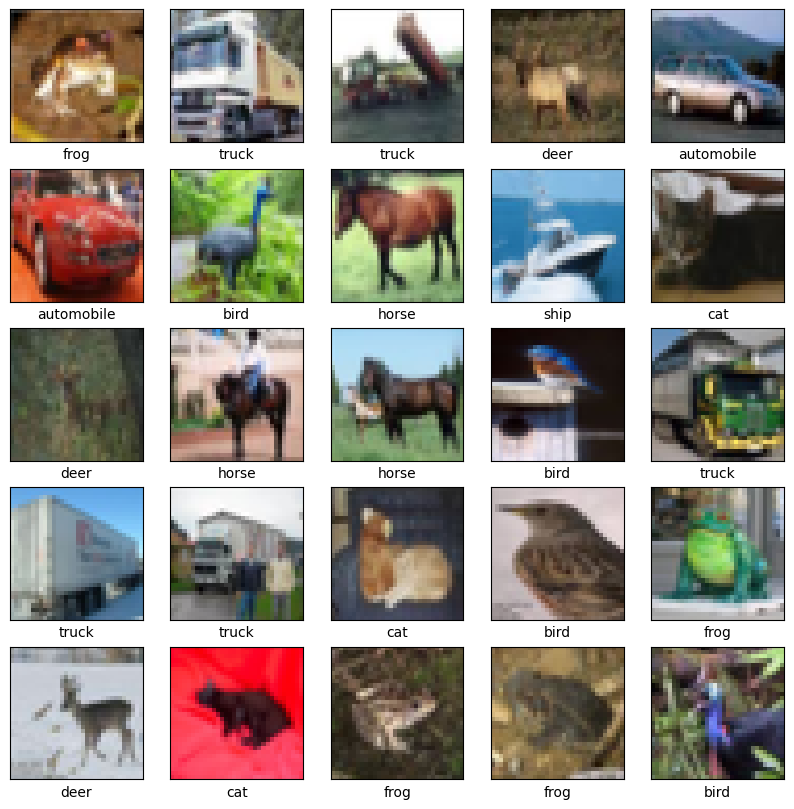

In [10]:
plt.figure(figsize=(10, 10))
for index in range(25):
  image, label = train_data[index]
  plt.subplot(5, 5, index + 1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(image.permute(1, 2, 0))
  plt.xlabel(class_names[label])
plt.show()

## Base Model

### **TASK: Base Model Training**

We begin with a small CNN trained directly on CIFAR-10. It serves as a baseline for understanding model behavior without prior knowledge. The model contains two convolution and pooling stages followed by two fully connected layers.

In [11]:
class BaseCNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.features = nn.Sequential(
      nn.Conv2d(3, 32, kernel_size=4),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),
      nn.Conv2d(32, 64, kernel_size=3),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),
    )
    self.classifier = nn.Sequential(
      nn.Flatten(),
      nn.Linear(64 * 6 * 6, 256),
      nn.ReLU(),
      nn.Linear(256, 10),
    )

  def forward(self, inputs):
    return self.classifier(self.features(inputs))

In [12]:
BATCH_SIZE = 256
EPOCHS = 100

train_loader = DataLoader(
  train_data, batch_size=BATCH_SIZE, shuffle=True,
  num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=PERSISTENT_WORKERS
)
test_loader = DataLoader(
  test_data, batch_size=BATCH_SIZE, shuffle=False,
  num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=PERSISTENT_WORKERS
)

base_model = BaseCNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(base_model.parameters(), lr=1e-3)

base_model_history = _train_model(
  base_model, train_loader, test_loader, loss_fn, optimizer, EPOCHS
)
_save_trained_model(base_model, base_model_history, 'base_model_pytorch')

Epochs:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 001/100: loss=1.6410, accuracy=0.4022, val_loss=1.4656, val_accuracy=0.4836
Epoch 002/100: loss=1.3002, accuracy=0.5375, val_loss=1.2366, val_accuracy=0.5608
Epoch 003/100: loss=1.1697, accuracy=0.5864, val_loss=1.1414, val_accuracy=0.5985
Epoch 004/100: loss=1.0775, accuracy=0.6198, val_loss=1.0432, val_accuracy=0.6333
Epoch 005/100: loss=1.0067, accuracy=0.6477, val_loss=1.0324, val_accuracy=0.6385
Epoch 006/100: loss=0.9432, accuracy=0.6693, val_loss=1.0229, val_accuracy=0.6444
Epoch 007/100: loss=0.8936, accuracy=0.6892, val_loss=0.9577, val_accuracy=0.6674
Epoch 008/100: loss=0.8464, accuracy=0.7062, val_loss=0.9347, val_accuracy=0.6756
Epoch 009/100: loss=0.8013, accuracy=0.7211, val_loss=0.9189, val_accuracy=0.6863
Epoch 010/100: loss=0.7595, accuracy=0.7377, val_loss=0.9583, val_accuracy=0.6706
Epoch 011/100: loss=0.7178, accuracy=0.7500, val_loss=0.8995, val_accuracy=0.6880
Epoch 012/100: loss=0.6796, accuracy=0.7658, val_loss=0.8726, val_accuracy=0.6979
Epoch 013/100: l

### **TASK: Training Curve**

Plot the training curve and interpret it: Was the training successful? Did it stop at the right time?

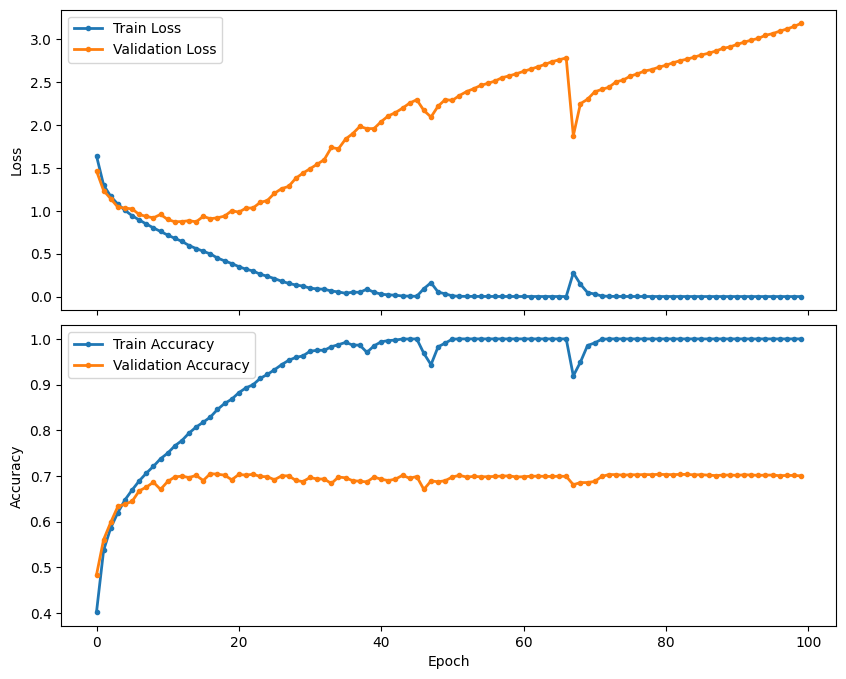

In [13]:
base_model_history, base_model = _load_trained_model(
  BaseCNN(), 'base_model_pytorch'
)
_process_history(base_model_history)

The training curves typically show classic **overfitting**: training loss continues to decrease while validation loss eventually rises, and training accuracy becomes substantially higher than validation accuracy. Early stopping or stronger regularization would improve generalization.

## Advanced Model

### **TASK: Advanced Model Training**

The advanced CNN uses data augmentation, He initialization, batch normalization, and increasing dropout rates. Augmentation is part of the training dataset transform and is therefore applied only to training images.

In [16]:
advanced_train_transform = transforms.Compose([
  transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
  transforms.RandomHorizontalFlip(),
  transforms.RandomRotation(36),
  transforms.ToTensor(),
])

advanced_train_data = datasets.CIFAR10(
  root=DATA_DIR, train=True, download=False,
  transform=advanced_train_transform
)

In [17]:
class AdvancedCNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.features = nn.Sequential(
      nn.Conv2d(3, 32, kernel_size=3, padding=1),
      nn.BatchNorm2d(32),
      nn.ReLU(),
      nn.Conv2d(32, 32, kernel_size=3, padding=1),
      nn.BatchNorm2d(32),
      nn.ReLU(),
      nn.MaxPool2d(2),
      nn.Dropout(0.2),

      nn.Conv2d(32, 64, kernel_size=3, padding=1),
      nn.BatchNorm2d(64),
      nn.ReLU(),
      nn.Conv2d(64, 64, kernel_size=3, padding=1),
      nn.BatchNorm2d(64),
      nn.ReLU(),
      nn.MaxPool2d(2),
      nn.Dropout(0.3),

      nn.Conv2d(64, 128, kernel_size=3, padding=1),
      nn.BatchNorm2d(128),
      nn.ReLU(),
      nn.Conv2d(128, 128, kernel_size=3, padding=1),
      nn.BatchNorm2d(128),
      nn.ReLU(),
      nn.MaxPool2d(2),
      nn.Dropout(0.4),
    )
    self.classifier = nn.Sequential(
      nn.Flatten(),
      nn.Linear(128 * 4 * 4, 128),
      nn.BatchNorm1d(128),
      nn.ReLU(),
      nn.Dropout(0.5),
      nn.Linear(128, 10),
    )
    self.apply(self._initialize_weights)
    nn.init.kaiming_uniform_(
      self.classifier[1].weight, nonlinearity='relu'
    )
    nn.init.zeros_(self.classifier[1].bias)

  @staticmethod
  def _initialize_weights(module):
    if isinstance(module, nn.Conv2d):
      nn.init.kaiming_uniform_(module.weight, nonlinearity='relu')
      if module.bias is not None:
        nn.init.zeros_(module.bias)

  def forward(self, inputs):
    return self.classifier(self.features(inputs))

In [21]:
BATCH_SIZE = 256
EPOCHS = 100

advanced_train_loader = DataLoader(
  advanced_train_data, batch_size=BATCH_SIZE, shuffle=True,
  num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=PERSISTENT_WORKERS
)
advanced_test_loader = DataLoader(
  test_data, batch_size=BATCH_SIZE, shuffle=False,
  num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=PERSISTENT_WORKERS
)

advanced_model = AdvancedCNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(advanced_model.parameters(), lr=1e-3)

advanced_model_history = _train_model(
  advanced_model, advanced_train_loader, advanced_test_loader,
  loss_fn, optimizer, EPOCHS
)
_save_trained_model(
  advanced_model, advanced_model_history, 'advanced_model_pytorch'
)

Epochs:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 001/100: loss=1.7646, accuracy=0.3514, val_loss=1.4094, val_accuracy=0.4883
Epoch 002/100: loss=1.4797, accuracy=0.4597, val_loss=1.2473, val_accuracy=0.5476
Epoch 003/100: loss=1.3613, accuracy=0.5052, val_loss=1.1229, val_accuracy=0.5988
Epoch 004/100: loss=1.2839, accuracy=0.5378, val_loss=1.0359, val_accuracy=0.6208
Epoch 005/100: loss=1.2258, accuracy=0.5614, val_loss=0.9922, val_accuracy=0.6386
Epoch 006/100: loss=1.1738, accuracy=0.5843, val_loss=1.0054, val_accuracy=0.6454
Epoch 007/100: loss=1.1335, accuracy=0.5977, val_loss=0.8808, val_accuracy=0.6797
Epoch 008/100: loss=1.1003, accuracy=0.6112, val_loss=0.8866, val_accuracy=0.6845
Epoch 009/100: loss=1.0667, accuracy=0.6235, val_loss=0.8877, val_accuracy=0.6748
Epoch 010/100: loss=1.0346, accuracy=0.6358, val_loss=0.8591, val_accuracy=0.6912
Epoch 011/100: loss=1.0057, accuracy=0.6476, val_loss=0.8313, val_accuracy=0.7100
Epoch 012/100: loss=0.9889, accuracy=0.6547, val_loss=0.7541, val_accuracy=0.7312
Epoch 013/100: l

### **TASK: Training Curve**

Plot the training curve and interpret it: Was the training successful? Did it stop at the right time?

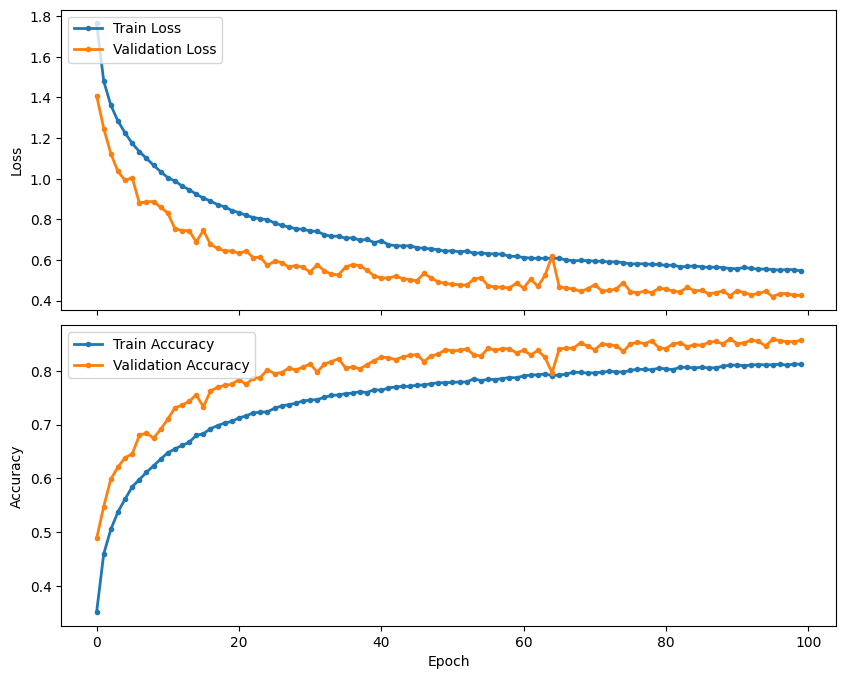

In [22]:
advanced_model_history, advanced_model = _load_trained_model(
  AdvancedCNN(), 'advanced_model_pytorch'
)
_process_history(advanced_model_history)

With augmentation and regularization, training and validation metrics should remain closer together than for the baseline. The exact plateau and optimal stopping point depend on the random seed, device, and PyTorch version.

## Transfer Learning Model

### **TASK: Transfer Learning with Pretrained ResNet50**

We load a ResNet50 pretrained on ImageNet, freeze its pretrained parameters, and replace the final classification layer with a trainable layer for the 10 CIFAR-10 classes. Images are resized to 224 × 224 and normalized with the statistics expected by the pretrained weights.

In [27]:
weights = ResNet50_Weights.DEFAULT
imagenet_mean = weights.transforms().mean
imagenet_std = weights.transforms().std

transfer_train_transform = transforms.Compose([
  transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
  transforms.RandomHorizontalFlip(),
  transforms.RandomRotation(20),
  transforms.Resize((224, 224)),
  transforms.ToTensor(),
  transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])
transfer_test_transform = transforms.Compose([
  transforms.Resize((224, 224)),
  transforms.ToTensor(),
  transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

transfer_train_data = datasets.CIFAR10(
  root=DATA_DIR, train=True, download=False,
  transform=transfer_train_transform
)
transfer_test_data = datasets.CIFAR10(
  root=DATA_DIR, train=False, download=False,
  transform=transfer_test_transform
)

In [28]:
class TransferResNet50(nn.Module):
  def __init__(self, pretrained=True):
    super().__init__()
    selected_weights = ResNet50_Weights.DEFAULT if pretrained else None
    self.backbone = resnet50(weights=selected_weights)
    input_features = self.backbone.fc.in_features
    self.backbone.fc = nn.Identity()

    for parameter in self.backbone.parameters():
      parameter.requires_grad = False

    self.classifier = nn.Linear(input_features, 10)

  def train(self, mode=True):
    super().train(mode)
    # Keep frozen BatchNorm statistics unchanged during head training.
    self.backbone.eval()
    return self

  def forward(self, inputs):
    features = self.backbone(inputs)
    return self.classifier(features)


def build_transfer_model(pretrained=True):
  return TransferResNet50(pretrained=pretrained)

In [29]:
BATCH_SIZE = 64
EPOCHS = 20

transfer_train_loader = DataLoader(
    transfer_train_data, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=PERSISTENT_WORKERS
)
transfer_test_loader = DataLoader(
    transfer_test_data, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=PERSISTENT_WORKERS
)

transfer_model = build_transfer_model(pretrained=True).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    (parameter for parameter in transfer_model.parameters()
     if parameter.requires_grad),
    lr=1e-3,
)

transfer_model_history = _train_model(
    transfer_model, transfer_train_loader, transfer_test_loader,
    loss_fn, optimizer, EPOCHS
)
_save_trained_model(
    transfer_model, transfer_model_history, 'transfer_model_pytorch'
)

Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 001/20: loss=0.7255, accuracy=0.7686, val_loss=0.3374, val_accuracy=0.8873
Epoch 002/20: loss=0.5167, accuracy=0.8238, val_loss=0.3051, val_accuracy=0.8961
Epoch 003/20: loss=0.4840, accuracy=0.8332, val_loss=0.2868, val_accuracy=0.9033
Epoch 004/20: loss=0.4559, accuracy=0.8457, val_loss=0.2794, val_accuracy=0.9073
Epoch 005/20: loss=0.4424, accuracy=0.8469, val_loss=0.2720, val_accuracy=0.9084
Epoch 006/20: loss=0.4285, accuracy=0.8510, val_loss=0.2715, val_accuracy=0.9103
Epoch 007/20: loss=0.4211, accuracy=0.8548, val_loss=0.2651, val_accuracy=0.9117
Epoch 008/20: loss=0.4213, accuracy=0.8534, val_loss=0.2646, val_accuracy=0.9112
Epoch 009/20: loss=0.4105, accuracy=0.8583, val_loss=0.2632, val_accuracy=0.9121
Epoch 010/20: loss=0.4075, accuracy=0.8589, val_loss=0.2713, val_accuracy=0.9095
Epoch 011/20: loss=0.4045, accuracy=0.8583, val_loss=0.2770, val_accuracy=0.9077
Epoch 012/20: loss=0.4018, accuracy=0.8587, val_loss=0.2679, val_accuracy=0.9108
Epoch 013/20: loss=0.4003, a

### **TASK: Training Curve**

Plot the training curve and interpret it: Was the training successful? Did it stop at the right time?

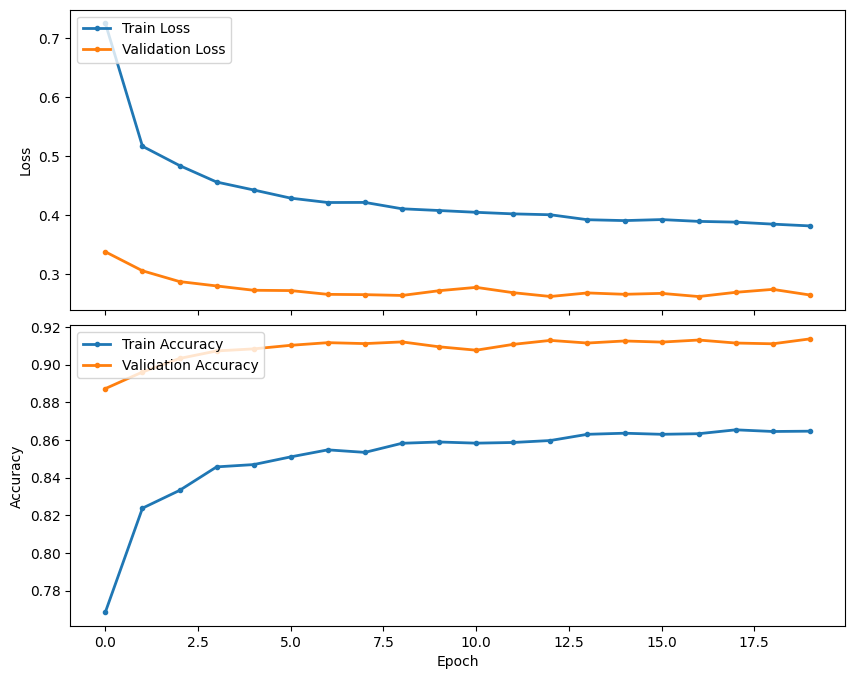

In [30]:
transfer_model_history, transfer_model = _load_trained_model(
  build_transfer_model(pretrained=False), 'transfer_model_pytorch'
)
_process_history(transfer_model_history)

The transfer model should converge more quickly because the frozen ResNet50 already provides useful visual features learned from ImageNet. Only the newly created classification layer is optimized in this exercise.

## Performance Comparison

### **TASK: Performance Comparison**

Compare the three models to analyze how model complexity, regularization, augmentation, and pretrained knowledge affect their training dynamics and validation performance.

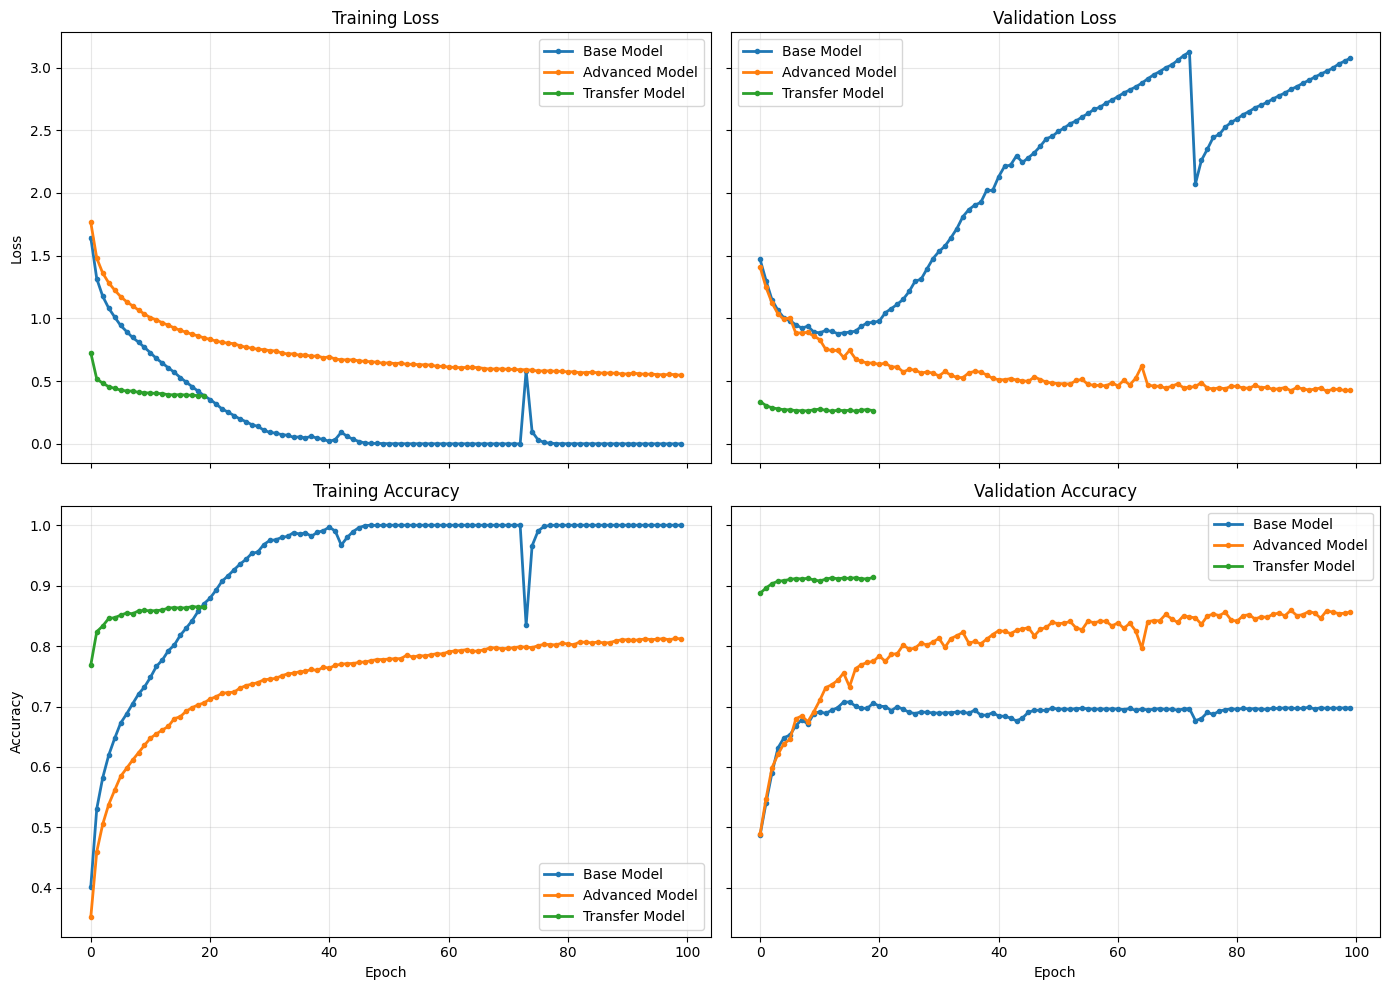

In [31]:
def _compare_models(model_histories):
  fig, axes = plt.subplots(
    2, 2, figsize=(14, 10), sharex=True, sharey='row'
  )
  colors = plt.cm.tab10.colors
  plots = [
    ('loss', 'Training Loss', axes[0, 0]),
    ('val_loss', 'Validation Loss', axes[0, 1]),
    ('accuracy', 'Training Accuracy', axes[1, 0]),
    ('val_accuracy', 'Validation Accuracy', axes[1, 1]),
  ]

  for metric, title, axis in plots:
    for index, (model_name, history) in enumerate(model_histories.items()):
      axis.plot(
        history[metric],
        label=model_name,
        linewidth=2,
        marker='o',
        markersize=3,
        color=colors[index % len(colors)],
      )
    axis.set_title(title)
    axis.legend()
    axis.grid(True, alpha=0.3)

  axes[0, 0].set_ylabel('Loss')
  axes[1, 0].set_ylabel('Accuracy')
  axes[1, 0].set_xlabel('Epoch')
  axes[1, 1].set_xlabel('Epoch')
  plt.tight_layout()
  plt.show()


model_histories = {
  'Base Model': base_model_history,
  'Advanced Model': advanced_model_history,
  'Transfer Model': transfer_model_history,
}

_compare_models(model_histories)